# DS3000 Project - Lab Section 5, Group 04, Dataset #16

## Stage 1: Data Understanding and Baselines

Dataset: Plant Leaf Diseases

Proposed objective: Predict the plant/disease category of a leaf image using supervised multiclass image classification. Each observation is one image containing exactly one distinct annotated category. Images with no label or with multiple distinct categories are excluded.

### Dataset and prediction task

We use version 10 of the Plant Leaf Diseases dataset from Roboflow Universe, downloaded in COCO JSON format. The dataset contains images and annotations identifying plant and disease categories.

Our task is supervised multiclass classification. One observation is one retained image, and the target is the single distinct category assigned to that image’s annotations. Category IDs represent class names rather than numerical quantities, so the target has no physical measurement unit.

Although the original dataset includes bounding boxes for object detection, our current approach classifies whole images. We retain images containing exactly one distinct annotated category. An image may contain several leaves as long as their annotations all belong to the same category.

In [6]:
import json
from pathlib import Path

data_folder = Path("data/plant_leaf_diseases")

def load_annotations(split):
    with open(data_folder / split / "_annotations.coco.json") as f:
        return json.load(f)

train_annotations = load_annotations("train")
valid_annotations = load_annotations("valid")
test_annotations = load_annotations("test")

# Load each split's COC annotations into a dictionary

print("Training images:", len(train_annotations["images"]))
print("Validation images:", len(valid_annotations["images"]))
print("Test images:", len(test_annotations["images"]))
print("Annotations:", len(train_annotations["annotations"]))

#categories definitions are identical in all splits.
for category in train_annotations["categories"]:
    print(category["id"], " ", category["name"])

Training images: 3426
Validation images: 428
Test images: 428
Annotations: 11885
0   leaves
1   Apple Scab Leaf
2   Apple leaf
3   Apple rust leaf
4   Bell_pepper leaf
5   Bell_pepper leaf spot
6   Blueberry leaf
7   Cherry leaf
8   Corn Gray leaf spot
9   Corn leaf blight
10   Corn rust leaf
11   Peach leaf
12   Potato leaf
13   Potato leaf early blight
14   Potato leaf late blight
15   Raspberry leaf
16   Soyabean leaf
17   Soybean leaf
18   Squash Powdery mildew leaf
19   Strawberry leaf
20   Tomato Early blight leaf
21   Tomato Septoria leaf spot
22   Tomato leaf
23   Tomato leaf bacterial spot
24   Tomato leaf late blight
25   Tomato leaf mosaic virus
26   Tomato leaf yellow virus
27   Tomato mold leaf
28   Tomato two spotted spider mites leaf
29   grape leaf
30   grape leaf black rot


### Data cleaning and missingness

We load the image records, annotations, and category definitions separately for the training, validation, and test sets. Each image is linked to its annotated categories using its image ID.

We standardize the labels “Soybean leaf” and “Soyabean leaf” as one soybean category by mapping category ID 17 to ID 16 in every split. This prevents spelling variants of the same intended category from being treated as separate prediction targets.

We exclude images with no annotated category because they do not provide a target label. We also exclude images with multiple distinct categories because our current task requires one target category per image. These exclusions limit our analysis to images suitable for single-label classification.

We check whether every referenced image file exists and whether Pillow can fully load it. Missing or unreadable images are excluded from the retained image-label dictionaries. These operations exclude observations from the analysis without deleting the original image files or modifying the source annotations.

The printed outputs report the category-filtered counts and the missing/corrupt-image counts for each split. We exclude images with unavailable labels rather than guessing replacement labels.

In [7]:
# Store the unique categories found in each image


def get_image_labels(annotations):
    image_labels = {}
    for image in annotations["images"]:
        image_id = image["id"]
        image_labels[image_id] = set()

    for annotation in annotations["annotations"]:
        image_id = annotation["image_id"]
        category_id = annotation["category_id"]

        if category_id == 17:
            category_id = 16  #merge two soya beans together

        image_labels[image_id].add(category_id)
    return image_labels

test_image_labels = get_image_labels(test_annotations)
valid_image_labels = get_image_labels(valid_annotations)
train_image_labels = get_image_labels(train_annotations)


# Count images by how many different categories they contain
def print_image_label_stats(image_labels):
    print("No category:", 
          sum(len(labels) == 0 for labels in image_labels.values()))

    print("Exactly one category:",
          sum(len(labels) == 1 for labels in image_labels.values()))

    print("Multiple categories:",
          sum(len(labels) > 1 for labels in image_labels.values()))
print_image_label_stats(test_image_labels)
print_image_label_stats(valid_image_labels)
print_image_label_stats(train_image_labels)

No category: 1
Exactly one category: 425
Multiple categories: 2
No category: 2
Exactly one category: 422
Multiple categories: 4
No category: 16
Exactly one category: 3384
Multiple categories: 26


### Existing data split

The downloaded dataset provides training, validation, and test sets with an approximately 80/10/10 split. We preserve these assignments and apply the same cleaning rules to each split. Excluding unsuitable images changes the retained counts and may slightly change the percentages. Final retained counts are reported after cleaning and duplicate checking.

In [8]:
# Keep only images with exactly one distinct category

def filter_single_category_images(image_labels):
    single_category_labels = {}
    excluded_ids = []
    for image_id, labels in image_labels.items():
        if len(labels) == 1:
            single_category_labels[image_id] = labels
        else:
            excluded_ids.append(image_id)
    return single_category_labels, excluded_ids


train_single_category_labels, train_excluded_ids = filter_single_category_images(train_image_labels)
test_single_category_labels, test_excluded_ids = filter_single_category_images(test_image_labels)
valid_single_category_labels, valid_excluded_ids = filter_single_category_images(valid_image_labels)

print("Training images with a single category:", len(train_single_category_labels))
print("Validation images with a single category:", len(valid_single_category_labels))
print("Test images with a single category:", len(test_single_category_labels))


# checking for corrupt or missing images
from PIL import Image

def check_images(name, annotations, data_folder):
    missing_image_ids = []
    corrupt_image_ids = []
    for image in annotations["images"]:
        image_id = image["id"]
        image_path = data_folder / name / image["file_name"]

        if not image_path.is_file():
            missing_image_ids.append(image_id)
            continue

        try:
            with Image.open(image_path) as img:
                img.load()

        except (OSError, ValueError):
            corrupt_image_ids.append(image_id)
    return missing_image_ids, corrupt_image_ids

train_missing_image_ids, train_corrupt_image_ids = check_images("train", train_annotations, data_folder)
test_missing_image_ids, test_corrupt_image_ids = check_images("test", test_annotations, data_folder)
valid_missing_image_ids, valid_corrupt_image_ids = check_images("valid", valid_annotations, data_folder)


print("Training missing images:", len(train_missing_image_ids))
print("Training corrupt images:", len(train_corrupt_image_ids))
print("Validation missing images:", len(valid_missing_image_ids))
print("Validation corrupt images:", len(valid_corrupt_image_ids))
print("Test missing images:", len(test_missing_image_ids))
print("Test corrupt images:", len(test_corrupt_image_ids))


#get rid of corrupt and missing images
for image_id in train_missing_image_ids + train_corrupt_image_ids:
    train_single_category_labels.pop(image_id, None)

for image_id in valid_missing_image_ids + valid_corrupt_image_ids:
    valid_single_category_labels.pop(image_id, None)

for image_id in test_missing_image_ids + test_corrupt_image_ids:
    test_single_category_labels.pop(image_id, None)

print("Final training images:", len(train_single_category_labels))
print("Final validation images:", len(valid_single_category_labels))
print("Final test images:", len(test_single_category_labels))

Training images with a single category: 3384
Validation images with a single category: 422
Test images with a single category: 425
Training missing images: 24
Training corrupt images: 0
Validation missing images: 4
Validation corrupt images: 0
Test missing images: 1
Test corrupt images: 0
Final training images: 3360
Final validation images: 418
Final test images: 424


In [9]:
import hashlib
from PIL import Image

splits = {
    "test": (test_annotations, test_single_category_labels),
    "valid": (valid_annotations, valid_single_category_labels),
    "train": (train_annotations, train_single_category_labels),
}

seen_images = {}
duplicates = []
conflicting_labels = []

# Check test first, then validation, then training.
# For overlaps, keep the evaluation example and exclude its training copy.
for split, (annotations, retained_labels) in splits.items():
    for image in sorted(annotations["images"], key=lambda item: item["id"]):
        image_id = image["id"]

        if image_id not in retained_labels:
            continue

        image_path = data_folder / split / image["file_name"]

        with Image.open(image_path) as img:
            rgb = img.convert("RGB")
            signature = hashlib.sha256(
                str(rgb.size).encode() + rgb.tobytes()
            ).hexdigest()

        category_id = next(iter(retained_labels[image_id]))

        if signature in seen_images:
            previous_split, previous_id, previous_category = seen_images[signature]

            duplicates.append(
                (split, image_id, previous_split, previous_id)
            )

            if category_id != previous_category:
                conflicting_labels.append(
                    (split, image_id, previous_split, previous_id)
                )
        else:
            seen_images[signature] = (split, image_id, category_id)

print("Duplicate copies found:", len(duplicates))
print("Duplicates with conflicting labels:", len(conflicting_labels))

# Resolve inconsistent labels before automatically excluding duplicates.
if conflicting_labels:
    print("Conflicting image pairs:", conflicting_labels)
    raise ValueError("Review conflicting duplicate labels before continuing.")

for split, image_id, previous_split, previous_id in duplicates:
    splits[split][1].pop(image_id, None)

for split, (_, retained_labels) in splits.items():
    removed = sum(item[0] == split for item in duplicates)
    print(
        f"{split}: removed {removed} duplicate copies; "
        f"{len(retained_labels)} images retained"
    )

Duplicate copies found: 0
Duplicates with conflicting labels: 0
test: removed 0 duplicate copies; 424 images retained
valid: removed 0 duplicate copies; 418 images retained
train: removed 0 duplicate copies; 3360 images retained


### Duplicate handling and retained observations

We check retained images for exact duplicate pixel content by converting each image to RGB and hashing its dimensions and pixel values. This allows identical decoded images to be detected even when their filenames differ.

For matching images with consistent labels, we retain one copy. We process test images first, followed by validation and training images, so an exact copy found in an evaluation set is excluded from training. Conflicting labels trigger an error for review before duplicate exclusion proceeds.

The outputs above show the duplicate copies excluded and the final retained counts for each split. All later plots and model inputs use these cleaned image-label dictionaries.

This check identifies exact pixel duplicates. It does not detect all related images, such as crops or brightness-adjusted versions of the same original.

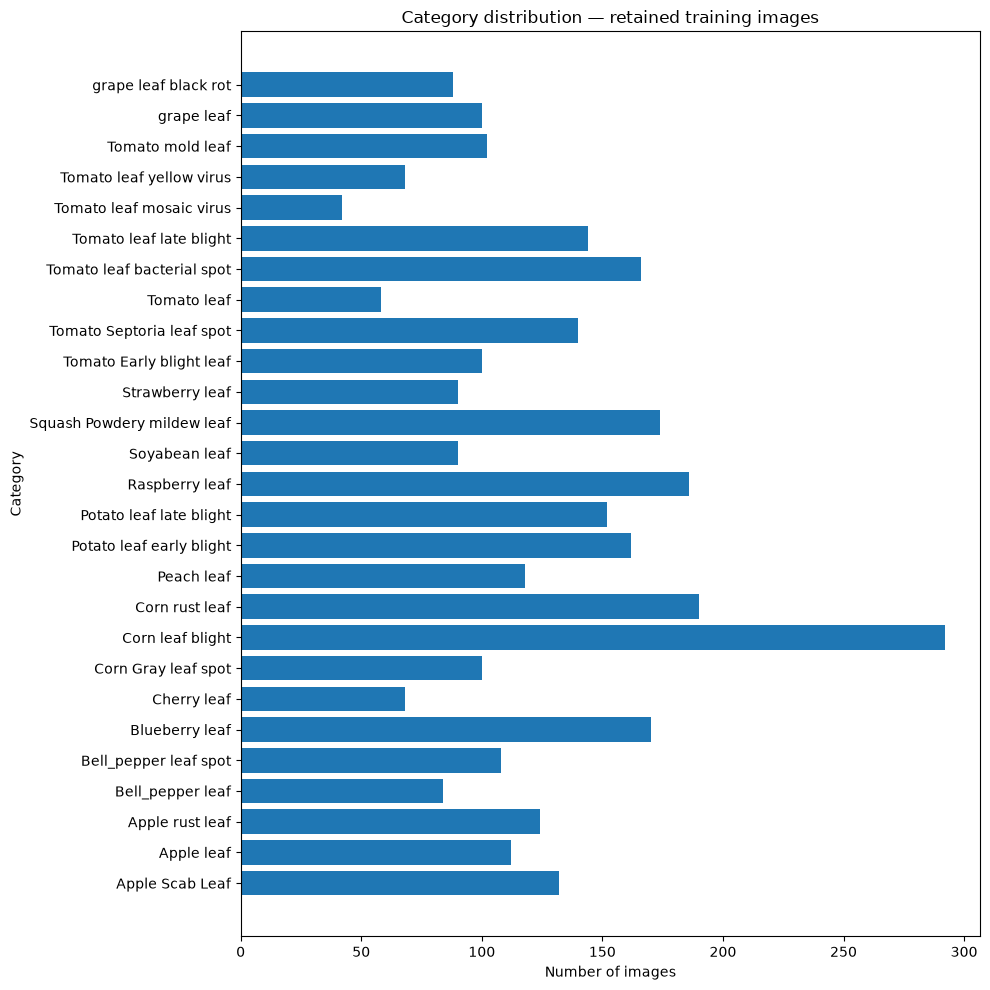

In [10]:
import matplotlib.pyplot as plt

category_counts = {}

for labels in train_single_category_labels.values():
    category_id = list(labels)[0]
    category_counts[category_id] = category_counts.get(category_id, 0) + 1

names = []
counts = []

for category in train_annotations["categories"]:
    category_id = category["id"]

    if category_id in category_counts:
        names.append(category["name"])
        counts.append(category_counts[category_id])

plt.figure(figsize=(10, 10))
plt.barh(names, counts)
plt.xlabel("Number of images")
plt.ylabel("Category")
plt.title("Category distribution — retained training images")
plt.tight_layout()
plt.show()

### Figure 1: Category Distribution of Retained Training Images

This figure counts retained training images in each category after cleaning and duplicate exclusion. Each image contributes once to its category’s count.

The distribution helps assess how much training evidence is available for each category. Categories with fewer examples may be harder to learn reliably, while categories with more examples can have greater influence on overall accuracy.

The training categories are unevenly represented. Corn leaf blight has considerably more images than other categories, while Tomato leaf mosaic virus has relatively few. This means the classifiers will have more training examples available for some categories than others.

This imbalance could lead to stronger performance on common categories and weaker performance on less represented ones. Overall accuracy could hide these differences, so we will also examine per-class results and macro-F1, which gives each category equal weight.

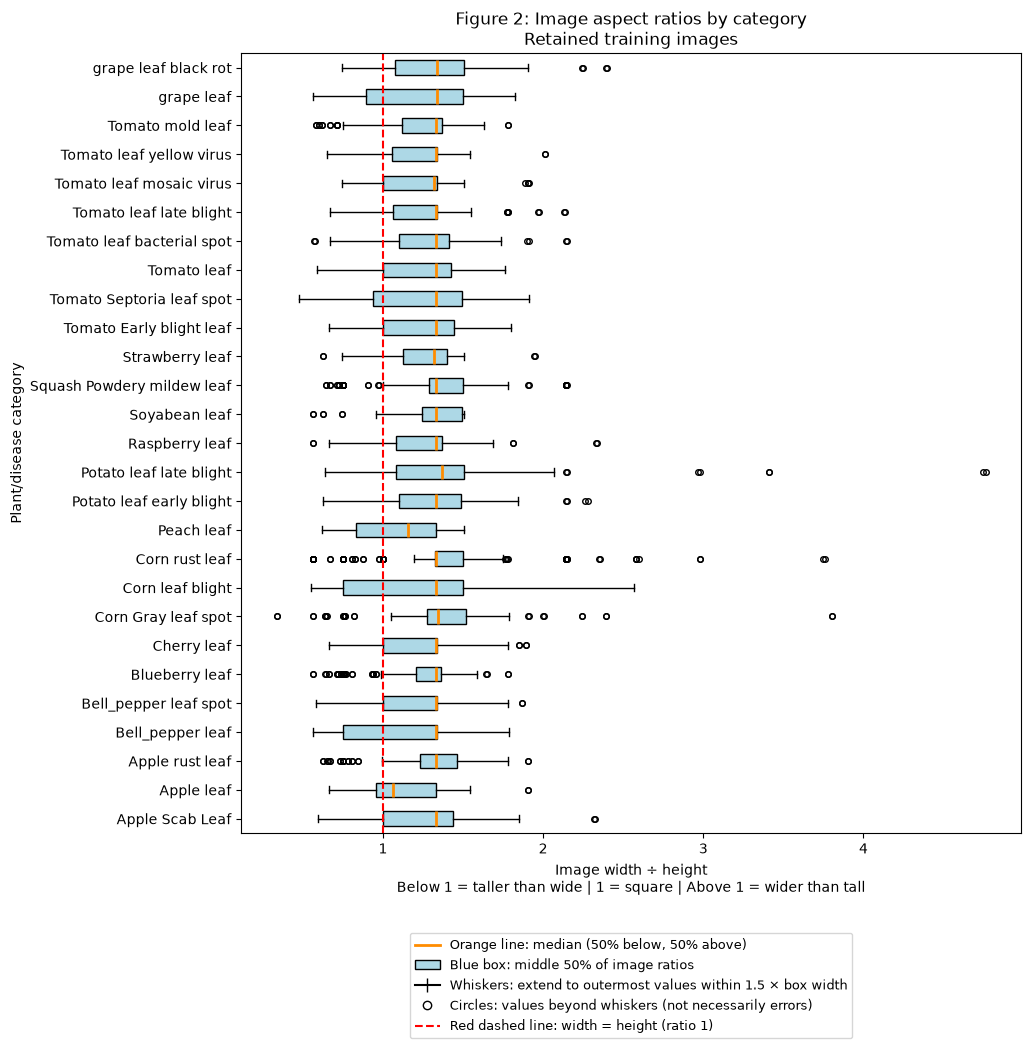

In [11]:
from PIL import Image
import matplotlib.pyplot as plt

aspect_ratios = {}

for image in train_annotations["images"]:
    image_id = image["id"]

    # Only use images retained after cleaning and duplicate removal.
    if image_id not in train_single_category_labels:
        continue

    category_id = next(iter(train_single_category_labels[image_id]))
    image_path = data_folder / "train" / image["file_name"]

    with Image.open(image_path) as img:
        width, height = img.size

    aspect_ratios.setdefault(category_id, []).append(width / height)

# Match category names to their measurements.
category_names = []
ratio_groups = []

for category in train_annotations["categories"]:
    category_id = category["id"]

    if category_id in aspect_ratios:
        category_names.append(category["name"])
        ratio_groups.append(aspect_ratios[category_id])

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(13, 12))

ax.boxplot(
    ratio_groups,
    orientation = "horizontal",
    tick_labels=category_names,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", edgecolor="black"),
    medianprops=dict(color="darkorange", linewidth=2),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
    flierprops=dict(
        marker="o",
        markerfacecolor="none",
        markeredgecolor="black",
        markersize=4
    )
)

# A ratio of 1 means the image's width equals its height.
ax.axvline(1, color="red", linestyle="--", linewidth=1.5)

legend_items = [
    Line2D(
        [0], [0], color="darkorange", linewidth=2,
        label="Orange line: median (50% below, 50% above)"
    ),
    Patch(
        facecolor="lightblue", edgecolor="black",
        label="Blue box: middle 50% of image ratios"
    ),
    Line2D(
        [0], [0], color="black", marker="|", markersize=10,
        label="Whiskers: extend to outermost values within 1.5 × box width"
    ),
    Line2D(
        [0], [0], marker="o", linestyle="none",
        markerfacecolor="none", markeredgecolor="black",
        label="Circles: values beyond whiskers (not necessarily errors)"
    ),
    Line2D(
        [0], [0], color="red", linestyle="--",
        label="Red dashed line: width = height (ratio 1)"
    )
]

ax.set_xlabel(
    "Image width ÷ height\n"
    "Below 1 = taller than wide | 1 = square | Above 1 = wider than tall"
)
ax.set_ylabel("Plant/disease category")
ax.set_title(
    "Figure 2: Image aspect ratios by category\n"
    "Retained training images"
)

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    fontsize=9,
    frameon=True
)

# Leave room beneath the graph for the explanatory legend.
fig.subplots_adjust(left=0.30, bottom=0.27, top=0.92)

plt.show()

### Figure 2: Image aspect ratios by category

Most categories have median aspect ratios slightly above 1, indicating that their typical images are wider than they are tall. There is also variation within categories, with some unusually wide images. For example, Potato leaf late blight includes an image with an aspect ratio of approximately 4.7.

These differences matter when preparing fixed-size image inputs for the classifiers. Stretching every image into a square would distort wide or tall images. Resizing while preserving proportions and adding padding would avoid this distortion, although very wide images would occupy a smaller portion of the square and could lose fine detail when reduced.

The plot therefore supports considering resizing with padding as an initial preprocessing approach. Validation results will be needed to assess how well that approach works.

## Part 2: Data Split Pipeline and Feature Engineering

### Data Split Choice
1. Training Set: This is used only for model optimization and fitting features.
2. Validation Set: This is used only for model comparison, metric evaluation, and hyperparameter tuning.
3. Test Set: Held out, untouched until the final evaluation.

In [12]:
# Split Summary
import pandas as pd

total_samples = len(train_single_category_labels) + len(valid_single_category_labels) + len(test_single_category_labels)

split_summary = pd.DataFrame([
    {"Split": "Training Set", "Images": len(train_single_category_labels),
     "Ratio": f"{len(train_single_category_labels)/total_samples*100:.1f}%",
     "Role": "Model fitting and scaler estimation"},
    {"Split": "Validation Set", "Images": len(valid_single_category_labels),
     "Ratio": f"{len(valid_single_category_labels)/total_samples*100:.1f}%",
     "Role": "Model comparison and metric evaluation"},
    {"Split": "Test Set", "Images": len(test_single_category_labels), 
     "Ratio": f"{len(test_single_category_labels)/total_samples*100:.1f}%", 
     "Role": "Held out; evaluated once in Stage 3"}
])
print("Data split summary:")
display(split_summary)

Data split summary:


,Split,Images,Ratio,Role
0,Training Set,3360,80.0%,Model fitting and scaler estimation
1,Validation Set,418,9.9%,Model comparison and metric evaluation
2,Test Set,424,10.1%,Held out; evaluated once in Stage 3


### 2. Feature Extraction & Leakage-Free Standardization

To feed image data into classical models:
1. Feature Construction: Each RGB image is resized to a standardized $32 \times 32$ spatial grid and flattened into a $32 \times 32 \times 3 = 3,072$-dimensional input vector normalized to $[0, 1]$.

2. Leakage Prevention: $z$-score standardization $x' = \frac{x - \mu}{\sigma}$ is fitted on the training split only. Validation features are transformed with the training mean and standard deviation, so no validation or test statistics are used during fitting. No imputer is needed because the images have no missing pixel values, and images with missing labels or files were removed during cleaning.

In [13]:
# Feature Extraction: 32x32 RGB Image Flattening & Training-Set Scaler
import numpy as np
from PIL import Image
from sklearn.preprocessing import StandardScaler

SIZE = 32

def extract_features(annotations, labels_dict, split_name):
    X, y = [], []
    cat_map = {c["id"]: c["name"] for c in annotations["categories"]}
    for img in annotations["images"]:
        if img["id"] in labels_dict:
          p = data_folder / split_name / img["file_name"]
          if not p.is_file():
            continue
                
          with Image.open(p) as im:
            arr = np.asarray(im.convert("RGB").resize((SIZE, SIZE))).ravel() / 255.0
          X.append(arr)
          cat_id = next(iter(labels_dict[img["id"]]))
          y.append(cat_map[cat_id])
    return np.array(X, dtype=np.float32), np.array(y)

print("Extracting features from Training and Validation sets...")
X_train, y_train = extract_features(train_annotations, train_single_category_labels, "train")
X_val, y_val = extract_features(valid_annotations, valid_single_category_labels, "valid")

# Fit scaler strictly on training data
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)

print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_val shape:   {X_val_scaled.shape}")

Extracting features from Training and Validation sets...
X_train shape: (3360, 3072)
X_val shape:   (418, 3072)


### Part 3: Baseline Model Development and Comparative Evaluation

### Model Families Covered:
1. Dummy Classifier (Most Frequent): Always predicts the most common training class. Any useful model should score above it.
2. Multinomial Logistic Regression: Probabilistic linear classifier optimizing log-likelihood / cross-entropy with $L_2$ regularization ($C=0.01$).
3. Support Vector Machine (SVM with RBF Kernel): Discriminative non-linear maximum-margin classifier with soft-margin parameter $C=10$.
4. K-Nearest Neighbors (KNN): Instance-based non-parametric classifier ($k=5$, Euclidean distance metric).

Hyperparameters (C=0.01, C=10, k=5) were fixed before training and not tuned. Tuning on the validation set is done in Stage 2. The parameter count is 0 for Dummy and KNN: KNN has no fitted weights and instead stores all 3384 training vectors.

### Justification of Primary Metric: Why Macro F1?
Because classes are imbalanced (Figure 1), standard accuracy is misleading: a model predicting only majority classes yields high accuracy while completely failing on rare diseases. Macro F1 computes the unweighted harmonic mean across all classes, giving equal weight to critical rare crop diseases.

In [14]:
# Train Baselines & Compile Performance Comparison Table
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

SEED = 42
models = {
    "Dummy (Most Frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, C=0.01, random_state=SEED),
    "SVM (RBF Kernel)": SVC(C=10, random_state=SEED),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5)
}

def get_param_count(name, m):
    if "Logistic" in name: 
        return m.coef_.size + m.intercept_.size
    elif "SVM" in name: 
        return m.support_vectors_.size + m.dual_coef_.size + m.intercept_.size
    return 0

results = []
for name, m in models.items():
    t0 = time.perf_counter()
    m.fit(X_train_scaled, y_train)
    t_train = time.perf_counter() - t0
    
    t0 = time.perf_counter()
    preds = m.predict(X_val_scaled)
    t_infer = time.perf_counter() - t0
    
    results.append({
        "Model": name,
        "Val Accuracy": accuracy_score(y_val, preds),
        "Val Macro F1": f1_score(y_val, preds, average="macro", zero_division=0),
        "Val Macro Recall": recall_score(y_val, preds, average="macro", zero_division=0),
        "Val Macro Precision": precision_score(y_val, preds, average="macro", zero_division=0),
        "Parameters": get_param_count(name, m),
        "Train Time (s)": t_train,
        "Infer Latency (ms/img)": 1000 * t_infer / len(y_val)
    })

results_df = pd.DataFrame(results)
dummy_f1 = results_df.loc[results_df["Model"] == "Dummy (Most Frequent)", "Val Macro F1"].iloc[0]
results_df["F1 Gain vs Dummy"] = results_df["Val Macro F1"] - dummy_f1

print("Stage 1 Baseline Comparison Table (Evaluated on Validation Split):")
display(results_df.round(4))

Stage 1 Baseline Comparison Table (Evaluated on Validation Split):


,Model,Val Accuracy,Val Macro F1,Val Macro Recall,Val Macro Precision,Parameters,Train Time (s),Infer Latency (ms/img),F1 Gain vs Dummy
0,Dummy (Most Frequent),0.0694,0.0048,0.0370,0.0026,0,0.0017,0.0006,0.0000
1,Logistic Regression,0.1292,0.0877,0.1021,0.1058,82971,88.6946,0.0064,0.0829
2,SVM (RBF Kernel),0.1746,0.1283,0.1538,0.1599,10381749,29.9909,7.2687,0.1235
3,KNN (k=5),0.1100,0.0729,0.0897,0.0793,0,0.0067,0.4576,0.0681


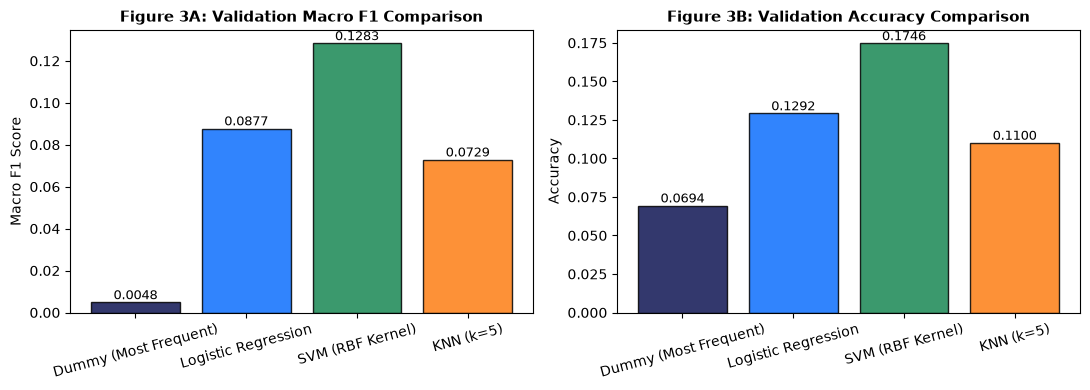

In [15]:
# Figure 3: Baseline Performance Comparison Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#0f1554", "#0d6efd", "#198754", "#fd7e14"]

bars1 = ax1.bar(results_df["Model"], results_df["Val Macro F1"], color=colors, edgecolor="black", alpha=0.85)
ax1.set_title("Figure 3A: Validation Macro F1 Comparison", fontsize = 11, fontweight="bold")
ax1.set_ylabel("Macro F1 Score")
ax1.tick_params(axis='x', rotation=15)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.0001, f"{yval:.4f}", ha='center', va='bottom', fontsize=9)

bars2 = ax2.bar(results_df["Model"], results_df["Val Accuracy"], color=colors, edgecolor="black", alpha=0.85)
ax2.set_title("Figure 3B: Validation Accuracy Comparison", fontsize=11, fontweight="bold")
ax2.set_ylabel("Accuracy")
ax2.tick_params(axis='x', rotation=15)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.0001, f"{yval:.4f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Part 4: Conclusions & Risks

### Conclusions from Stage 1:
1. Demonstrated Learning Above Chance Floor: All classical models beat the Dummy majority baseline (Macro F1 = 0.0048, Accuracy = 6.87%). The SVM with RBF Kernel achieves the strongest validation performance (17.54% accuracy, 0.1290 Macro F1, representing an absolute gain of +0.1243 over the dummy baseline).
2. Underfitting on raw pixels: The best model reaches only about 17.5% validation accuracy. Each image is shrunk to 32 × 32 and flattened into one long vector, so the models lose which pixels were next to each other. A disease spot in a different part of the image looks like completely different input. Small details such as lesions are also mostly lost at 32 × 32.

### Risks for Next Stages:
1. Background Memorization Bias: Stock images with plain white backdrops versus outdoor field photos with soil may cause pixel-level models to memorize background illumination rather than leaf pathology.
2. Severe Class Imbalance: Extreme category frequency differences hinder generalization on rare disease classes.
3. Stage 2 & 3 Roadmap: In Stage 2 (Lab 8), we will test tree-based ensembles (Random Forest, XGBoost) and MLPs with hyperparameter tuning on validation data. In Stage 3 (Lab 11), we will train a Convolutional Neural Network (CNN), which looks at small neighbouring pixel regions and can detect the same pattern wherever it appears in the image.

## Stage 2 · Multilayer Perceptron

### Model and input representations

We use a multilayer perceptron (MLP) to predict one plant or disease
category per image. The model has one fully connected hidden layer with
ReLU activation and one output score per class. The highest score
determines the predicted class.

We compare five representations of each 32 × 32 RGB image:

| Input representation | Features | Information retained |
|---|---:|---|
| Flattened RGB pixels | 3,072 | Red, green, and blue values at every pixel position. |
| Global RGB histogram (1 × 1) | 48 | Colour intensity distributions across the whole image. |
| Quadrant RGB histograms (2 × 2) | 192 | Colour intensity distributions in four 16 × 16 regions. |
| 4 × 4 RGB histograms | 768 | Colour intensity distributions in sixteen 8 × 8 regions. |
| 8 × 8 RGB histograms | 3,072 | Colour intensity distributions in sixty-four 4 × 4 regions. |

Each histogram uses 16 intensity bins per colour channel in each region (Compares intensity of R G and B divided 16 times for each colour)
Finer grids retain more location information, while each histogram is
estimated from fewer pixels.

### Training and evaluation

We train with multiclass cross-entropy to measure the model's error during training, and Adam to adjust the weights and biases. We first tune the MLP
using flattened pixels, then reuse the selected training settings (Number of hidden neurons, class weighting method, alpha values) for the
histogram comparison. All representations use the same training and
validation images. We standardize each feature using its training average and spread to help the MLP learn from inputs with different ranges of values (Some bins might have more pixels than others so we compare it with the average number of pixels per bin).

We use validation macro F1 to select checkpoints and compare models
because it gives each class equal weight. We report accuracy alongside it
and reserve the test split for final evaluation.

### MLP search plan

| Step | Input | What we compare | Trials |
|---|---|---|---:|
| 1. Tune width and class weighting | Flattened RGB pixels | Cross 64 and 128 hidden units with unweighted and inverse-square-root-frequency cross-entropy. Set weight decay to zero. | 4 |
| 2. Test weight decay | Flattened RGB pixels | Keep the best width and class weighting from Step 1. Compare weight decay values of 0.001 and 0.01 against its zero-decay result. | 2 |
| 3. Compare histogram grids | RGB histograms | Train one MLP for each grid size (1 × 1, 2 × 2, 4 × 4, and 8 × 8) using the best settings from the flattened-pixel search. | 4 |

All trials use the same training and validation images. We compute class
weights from training class counts and fit a separate scaler on the
training features for each histogram representation.

Each trial uses seed 42, Adam with a learning rate of 0.001, and shuffled
mini-batches of 64. We allow up to 60 epochs per trial, for a maximum of
600 epochs across all 10 trials. A trial stops after 10 consecutive epochs
without a strict improvement in validation macro F1.

For each trial, we keep the earliest epoch that achieves its best
validation macro F1. For exact ties in the flattened-pixel search, we
prefer fewer parameters, then unweighted loss, then lower weight decay.
We compare the best pixel model and the four histogram models by
validation macro F1, preferring fewer parameters on an exact tie.

In [44]:
from copy import deepcopy
from itertools import product
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


# Shared training settings
MLP_SEED = 42
MLP_BATCH_SIZE = 64
MLP_LEARNING_RATE = 0.001
MLP_MAX_EPOCHS = 60
MLP_PATIENCE = 10
MLP_CHECKPOINT = Path("artifacts/stage2_mlp.pt")

# Initial search grid for flattened RGB pixels
MLP_GRID = list(product(
    (64, 128),
    ("Unweighted", "Inverse sqrt frequency"),
))


# Fit one label mapping on the training set and reuse it for validation.
mlp_encoder = LabelEncoder().fit(y_train)
mlp_classes = mlp_encoder.classes_.tolist()
mlp_class_count = len(mlp_classes)

mlp_train_y = torch.as_tensor(mlp_encoder.transform(y_train), dtype=torch.long)
mlp_val_y = torch.as_tensor(mlp_encoder.transform(y_val), dtype=torch.long)

# Rare classes receive larger weights in the weighted training trials.
mlp_class_counts = torch.bincount(mlp_train_y, minlength=mlp_class_count)
mlp_class_weights = mlp_class_counts.float().rsqrt()


# Reuse the standardized flattened pixels from Stage 1.
mlp_train_x = torch.as_tensor(X_train_scaled, dtype=torch.float32, device="cpu")
mlp_val_x = torch.as_tensor(X_val_scaled, dtype=torch.float32, device="cpu")
mlp_input_dim = mlp_train_x.shape[1]
mlp_train_data = TensorDataset(mlp_train_x, mlp_train_y)


def build_mlp(input_dim, hidden_width, class_count):
    """Build a one-hidden-layer MLP that returns raw class scores."""
    return nn.Sequential(
        nn.Linear(input_dim, hidden_width),
        nn.ReLU(),
        nn.Linear(hidden_width, class_count),
    )


@torch.inference_mode()
def mlp_learning_metrics(model, features, targets):
    """Measure loss, macro F1, and accuracy without updating the model."""
    model.eval()
    logits = model(features)
    predictions = logits.argmax(dim=1).numpy()
    labels = targets.numpy()

    # Use the same unweighted loss for every trial's learning curves.
    loss = F.cross_entropy(logits, targets).item()
    macro_f1 = f1_score(labels, predictions, average="macro", zero_division=0)
    accuracy = accuracy_score(labels, predictions)

    return loss, macro_f1, accuracy

In [45]:
def train_mlp_trial(
    hidden_width,
    weighting,
    weight_decay,
    *,
    train_x=mlp_train_x,
    val_x=mlp_val_x,
):
    """Train one MLP and return its best metrics, history, and weights."""
    torch.manual_seed(MLP_SEED)
    model = build_mlp(train_x.shape[1], hidden_width, mlp_class_count)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=MLP_LEARNING_RATE,
        weight_decay=weight_decay,
    )
    class_weights = None if weighting == "Unweighted" else mlp_class_weights
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    batches = DataLoader(
        TensorDataset(train_x, mlp_train_y),
        batch_size=MLP_BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(MLP_SEED),
    )

    history = []
    best_val_f1 = -1.0
    best_epoch = 0
    fit_time = 0.0
    trial_start = perf_counter()

    for epoch in range(1, MLP_MAX_EPOCHS + 1):
        fit_start = perf_counter()
        model.train()

        for features, targets in batches:
            optimizer.zero_grad()
            loss = criterion(model(features), targets)
            loss.backward()
            optimizer.step()

        fit_time += perf_counter() - fit_start

        train_loss, train_f1, train_acc = mlp_learning_metrics(
            model, train_x, mlp_train_y
        )
        val_loss, val_f1, val_acc = mlp_learning_metrics(
            model, val_x, mlp_val_y
        )

        history.append({
            "Epoch": epoch,
            "Train Cross-Entropy": train_loss,
            "Val Cross-Entropy": val_loss,
            "Train Macro F1": train_f1,
            "Val Macro F1": val_f1,
            "Train Accuracy": train_acc,
            "Val Accuracy": val_acc,
        })

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())

        if epoch - best_epoch >= MLP_PATIENCE:
            break

    best_metrics = history[best_epoch - 1]
    trial = {
        "Hidden Width": hidden_width,
        "Class Weighting": weighting,
        "Weight Decay": weight_decay,
        "Best Epoch": best_epoch,
        "Epochs Run": epoch,
        "Train Macro F1": best_metrics["Train Macro F1"],
        "Val Macro F1": best_metrics["Val Macro F1"],
        "Train Accuracy": best_metrics["Train Accuracy"],
        "Val Accuracy": best_metrics["Val Accuracy"],
        "Parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "Train Time (s)": fit_time,
        "Trial Wall Time (s)": perf_counter() - trial_start,
    }

    return trial, pd.DataFrame(history), best_state


def mlp_trial_rank(entry):
    trial, _, _ = entry
    return (
        -trial["Val Macro F1"],
        trial["Parameters"],
        trial["Class Weighting"] != "Unweighted",
        trial["Weight Decay"],
    )


# Step 1: Compare hidden width and class weighting at zero weight decay.
mlp_trials = [
    train_mlp_trial(width, weighting, weight_decay=0.0)
    for width, weighting in MLP_GRID
]
initial_winner, _, _ = min(mlp_trials, key=mlp_trial_rank)

# Step 2: Test weight decay on the configuration that won Step 1.
mlp_trials.extend(
    train_mlp_trial(
        initial_winner["Hidden Width"],
        initial_winner["Class Weighting"],
        weight_decay,
    )
    for weight_decay in (0.001, 0.01)
)

mlp_trials.sort(key=mlp_trial_rank)
mlp_best, mlp_history, mlp_best_state = mlp_trials[0]
mlp_trial_table = pd.DataFrame([trial for trial, _, _ in mlp_trials])

print("Flattened RGB pixels · MLP search results")
display(mlp_trial_table.round(4))

print(
    f"Selected pixel MLP: {mlp_best['Hidden Width']} hidden units, "
    f"{mlp_best['Class Weighting'].lower()} loss, "
    f"weight decay {mlp_best['Weight Decay']:g}."
)
print(f"Total search wall time: {mlp_trial_table['Trial Wall Time (s)'].sum():.3f} s")

Flattened RGB pixels · MLP search results


,Hidden Width,Class Weighting,Weight Decay,Best Epoch,Epochs Run,Train Macro F1,Val Macro F1,Train Accuracy,Val Accuracy,Parameters,Train Time (s),Trial Wall Time (s)
0,128,Inverse sqrt frequency,0.000,10,20,0.9700,0.1206,0.9664,0.1675,396827,2.4372,2.7413
1,64,Unweighted,0.000,30,40,0.9961,0.1201,0.9961,0.1555,198427,4.9465,5.3690
2,64,Inverse sqrt frequency,0.000,2,12,0.3807,0.1199,0.3798,0.1531,198427,1.0925,1.2200
3,128,Inverse sqrt frequency,0.010,3,13,0.5360,0.1188,0.5289,0.1603,396827,1.4391,1.6235
4,128,Unweighted,0.000,9,19,0.9509,0.1169,0.9515,0.1651,396827,2.0547,2.3315
5,128,Inverse sqrt frequency,0.001,10,20,0.9585,0.1041,0.9524,0.1531,396827,2.3719,2.6594


Selected pixel MLP: 128 hidden units, inverse sqrt frequency loss, weight decay 0.
Total search wall time: 15.945 s


In [52]:
HIST_BINS_PER_CHANNEL = 16


def rgb_histogram_features(features, grid_size):
    """Create normalized RGB histograms for each region of an image."""
    images = np.asarray(features).reshape(-1, SIZE, SIZE, 3)
    region_size = SIZE // grid_size
    feature_count = grid_size**2 * 3 * HIST_BINS_PER_CHANNEL
    histograms = np.empty((len(images), feature_count), dtype=np.float32)

    for image_index, image in enumerate(images):
        offset = 0
        for row in range(grid_size):
            for col in range(grid_size):
                region = image[
                    row * region_size : (row + 1) * region_size,
                    col * region_size : (col + 1) * region_size,
                ]
                for channel in range(3):
                    pixels = region[:, :, channel]
                    counts, _ = np.histogram(
                        pixels, bins=HIST_BINS_PER_CHANNEL, range=(0, 1)
                    )
                    end = offset + HIST_BINS_PER_CHANNEL
                    histograms[image_index, offset:end] = counts / pixels.size
                    offset = end

    return histograms


histogram_runs = {}

for name, grid_size in [
    ("Global RGB histogram", 1),
    ("Quadrant RGB histograms", 2),
    ("4 × 4 RGB histograms", 4),
    ("8 × 8 RGB histograms", 8),
]:
    print(f"Training {name}...", flush=True)

    # Build histograms from RGB values before pixel standardization.
    train_hist = rgb_histogram_features(X_train, grid_size)
    val_hist = rgb_histogram_features(X_val, grid_size)

    hist_scaler = StandardScaler().fit(train_hist)
    hist_train_x = torch.as_tensor(
        hist_scaler.transform(train_hist), dtype=torch.float32
    )
    hist_val_x = torch.as_tensor(
        hist_scaler.transform(val_hist), dtype=torch.float32
    )

    trial, history, best_state = train_mlp_trial(
        hidden_width=mlp_best["Hidden Width"],
        weighting=mlp_best["Class Weighting"],
        weight_decay=mlp_best["Weight Decay"],
        train_x=hist_train_x,
        val_x=hist_val_x,
    )

    histogram_runs[name] = {
        "trial": trial,
        "history": history,
        "best_state": best_state,
        "scaler": hist_scaler,
        "grid_size": grid_size,
        "input_dim": hist_train_x.shape[1],
        "val_x": hist_val_x,
    }


mlp_input_comparison = pd.DataFrame([
    {
        "Input": "Flattened RGB pixels",
        "Features": mlp_input_dim,
        **mlp_best,
    },
    *[
        {
            "Input": name,
            "Features": run["input_dim"],
            **run["trial"],
        }
        for name, run in histogram_runs.items()
    ],
])

display(mlp_input_comparison[[
    "Input",
    "Features",
    "Parameters",
    "Best Epoch",
    "Epochs Run",
    "Train Accuracy",
    "Val Accuracy",
    "Train Macro F1",
    "Val Macro F1",
]].round(4))

Training Global RGB histogram...


Training Quadrant RGB histograms...
Training 4 × 4 RGB histograms...
Training 8 × 8 RGB histograms...


,Input,Features,Parameters,Best Epoch,Epochs Run,Train Accuracy,Val Accuracy,Train Macro F1,Val Macro F1
0,Flattened RGB pixels,3072,396827,10,20,0.9664,0.1675,0.9700,0.1206
1,Global RGB histogram,48,9755,30,40,0.3158,0.1770,0.3068,0.1355
2,Quadrant RGB histograms,192,28187,40,50,0.8315,0.1722,0.8414,0.1375
3,4 × 4 RGB histograms,768,101915,20,30,0.9970,0.1699,0.9969,0.1447
4,8 × 8 RGB histograms,3072,396827,2,12,0.8057,0.1531,0.8120,0.1268


### MLP results and baseline comparison

The table above compares five input representations using the same
training and validation images. We select the MLP variant with the
highest validation macro F1, preferring fewer parameters on an exact tie.

The learning curves below show training and validation performance for
the selected MLP. The dashed line marks its best validation epoch.
Improving training performance alongside flat or declining validation
performance indicates overfitting.

The comparison table includes all five MLP variants and the Stage 1
baselines. Validation macro F1 is the primary selection metric. Top-1
accuracy measures how often the first prediction is correct. Top-3
accuracy measures how often the correct class appears among the three
highest-ranked candidates. For KNN, only classes receiving a neighbour
vote count as candidates.

Training time covers the mini-batch training loops through the stopping
epoch. Inference latency measures prediction time per validation image
and excludes feature extraction, standardization, and metric calculation.

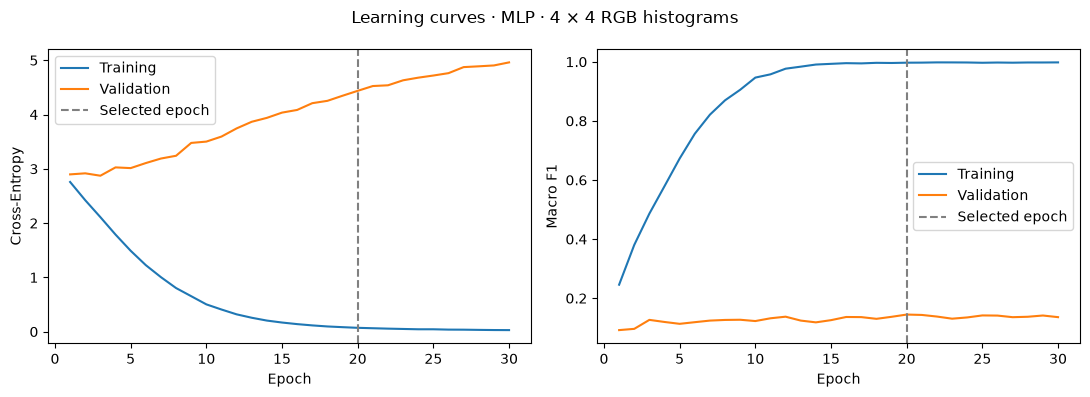

,Model,Val Accuracy,Val Top-3 Accuracy,Val Macro F1,Val Macro Recall,Val Macro Precision,Parameters,Train Time (s),Infer Latency (ms/img),F1 Gain vs Dummy
0,Dummy (Most Frequent),0.0694,NaN,0.0048,0.0370,0.0026,0,0.0017,0.0006,0.0000
1,Logistic Regression,0.1292,NaN,0.0877,0.1021,0.1058,82971,88.6946,0.0064,0.0829
2,SVM (RBF Kernel),0.1746,0.3182,0.1283,0.1538,0.1599,10381749,29.9909,7.2687,0.1235
3,KNN (k=5),0.1100,0.2416,0.0729,0.0897,0.0793,0,0.0067,0.4576,0.0681
4,MLP · Flattened RGB pixels,0.1675,0.2919,0.1206,0.1243,0.1465,396827,2.4372,0.2372,0.1158
5,MLP · Global RGB histogram,0.1770,0.3182,0.1355,0.1660,0.1433,9755,2.3085,0.0075,0.1307
6,MLP · Quadrant RGB histograms,0.1722,0.3158,0.1375,0.1561,0.1481,28187,3.5437,0.0132,0.1327
7,MLP · 4 × 4 RGB histograms,0.1699,0.3182,0.1447,0.1667,0.1772,101915,2.2829,0.0058,0.1399
8,MLP · 8 × 8 RGB histograms,0.1531,0.3038,0.1268,0.1467,0.1555,396827,1.9507,0.0370,0.1220


Selected MLP: MLP · 4 × 4 RGB histograms
Best epoch: 20 | Training macro F1: 0.9969 | Validation macro F1: 0.1447
Validation macro F1 vs. SVM (RBF Kernel): +0.0164


In [53]:
mlp_runs = {
    "MLP · Flattened RGB pixels": {
        "trial": mlp_best,
        "history": mlp_history,
        "best_state": mlp_best_state,
        "scaler": scaler,
        "grid_size": None,
        "input_dim": mlp_input_dim,
        "val_x": mlp_val_x,
    },
    **{f"MLP · {name}": run for name, run in histogram_runs.items()},
}

# Select by validation macro F1. Prefer fewer parameters on an exact tie.
selected_mlp_name, selected_mlp_run = min(
    mlp_runs.items(),
    key=lambda item: (
        -item[1]["trial"]["Val Macro F1"],
        item[1]["trial"]["Parameters"],
    ),
)
selected_mlp_trial = selected_mlp_run["trial"]
selected_mlp_history = selected_mlp_run["history"]

# Plot learning curves for the selected input representation.
mlp_fig, mlp_axes = plt.subplots(1, 2, figsize=(11, 4))

for axis, metric in zip(mlp_axes, ("Cross-Entropy", "Macro F1")):
    axis.plot(
        selected_mlp_history["Epoch"],
        selected_mlp_history[f"Train {metric}"],
        label="Training",
    )
    axis.plot(
        selected_mlp_history["Epoch"],
        selected_mlp_history[f"Val {metric}"],
        label="Validation",
    )
    axis.axvline(
        selected_mlp_trial["Best Epoch"],
        color="grey",
        linestyle="--",
        label="Selected epoch",
    )
    axis.set(xlabel="Epoch", ylabel=metric)
    axis.legend()

mlp_fig.suptitle(f"Learning curves · {selected_mlp_name}")
mlp_fig.tight_layout()
plt.show()

# Evaluate each MLP using its best saved epoch and its own validation features.
mlp_result_rows = []

for name, run in mlp_runs.items():
    trial = run["trial"]
    model = build_mlp(run["input_dim"], trial["Hidden Width"], mlp_class_count)
    model.load_state_dict(run["best_state"])
    model.eval()

    with torch.inference_mode():
        inference_start = perf_counter()
        logits = model(run["val_x"])
        predicted_ids = logits.argmax(dim=1).numpy()
        inference_time = perf_counter() - inference_start

        top3_ids = logits.topk(k=3, dim=1).indices
        top3_accuracy = (top3_ids == mlp_val_y[:, None]).any(dim=1).float().mean().item()

    predicted_labels = mlp_encoder.inverse_transform(predicted_ids)
    val_f1 = f1_score(y_val, predicted_labels, average="macro", zero_division=0)

    mlp_result_rows.append({
        "Model": name,
        "Val Accuracy": accuracy_score(y_val, predicted_labels),
        "Val Top-3 Accuracy": top3_accuracy,
        "Val Macro F1": val_f1,
        "Val Macro Recall": recall_score(
            y_val, predicted_labels, average="macro", zero_division=0
        ),
        "Val Macro Precision": precision_score(
            y_val, predicted_labels, average="macro", zero_division=0
        ),
        "Parameters": trial["Parameters"],
        "Train Time (s)": trial["Train Time (s)"],
        "Infer Latency (ms/img)": 1000 * inference_time / len(y_val),
        "F1 Gain vs Dummy": val_f1 - dummy_f1,
    })

    if name == selected_mlp_name:
        selected_mlp_model = model
        selected_mlp_val_x = run["val_x"]

mlp_results = pd.DataFrame(mlp_result_rows)

# Add top-3 scores to a copy of the baseline table.
baseline_comparison = results_df.copy()
val_labels_column = np.asarray(y_val)[:, None]

svm = models["SVM (RBF Kernel)"]
svm_scores = svm.decision_function(X_val_scaled)
svm_top3_ids = np.argsort(-svm_scores, axis=1, kind="stable")[:, :3]
svm_top3_accuracy = (
    svm.classes_[svm_top3_ids] == val_labels_column
).any(axis=1).mean()

knn = models["KNN (k=5)"]
knn_scores = knn.predict_proba(X_val_scaled)
knn_top3_ids = np.argsort(-knn_scores, axis=1, kind="stable")[:, :3]
knn_top3_scores = np.take_along_axis(knn_scores, knn_top3_ids, axis=1)
knn_top3_accuracy = (
    (knn.classes_[knn_top3_ids] == val_labels_column)
    & (knn_top3_scores > 0)
).any(axis=1).mean()

baseline_comparison["Val Top-3 Accuracy"] = baseline_comparison["Model"].map({
    "SVM (RBF Kernel)": svm_top3_accuracy,
    "KNN (k=5)": knn_top3_accuracy,
})

stage2_mlp_comparison = pd.concat(
    [baseline_comparison, mlp_results], ignore_index=True
)
comparison_columns = stage2_mlp_comparison.columns.tolist()
comparison_columns.remove("Val Top-3 Accuracy")
comparison_columns.insert(2, "Val Top-3 Accuracy")
stage2_mlp_comparison = stage2_mlp_comparison[comparison_columns]

display(stage2_mlp_comparison.round(4))

best_baseline = results_df.loc[results_df["Val Macro F1"].idxmax()]
f1_change = selected_mlp_trial["Val Macro F1"] - best_baseline["Val Macro F1"]

print(f"Selected MLP: {selected_mlp_name}")
print(
    f"Best epoch: {selected_mlp_trial['Best Epoch']} | "
    f"Training macro F1: {selected_mlp_trial['Train Macro F1']:.4f} | "
    f"Validation macro F1: {selected_mlp_trial['Val Macro F1']:.4f}"
)
print(f"Validation macro F1 vs. {best_baseline['Model']}: {f1_change:+.4f}")

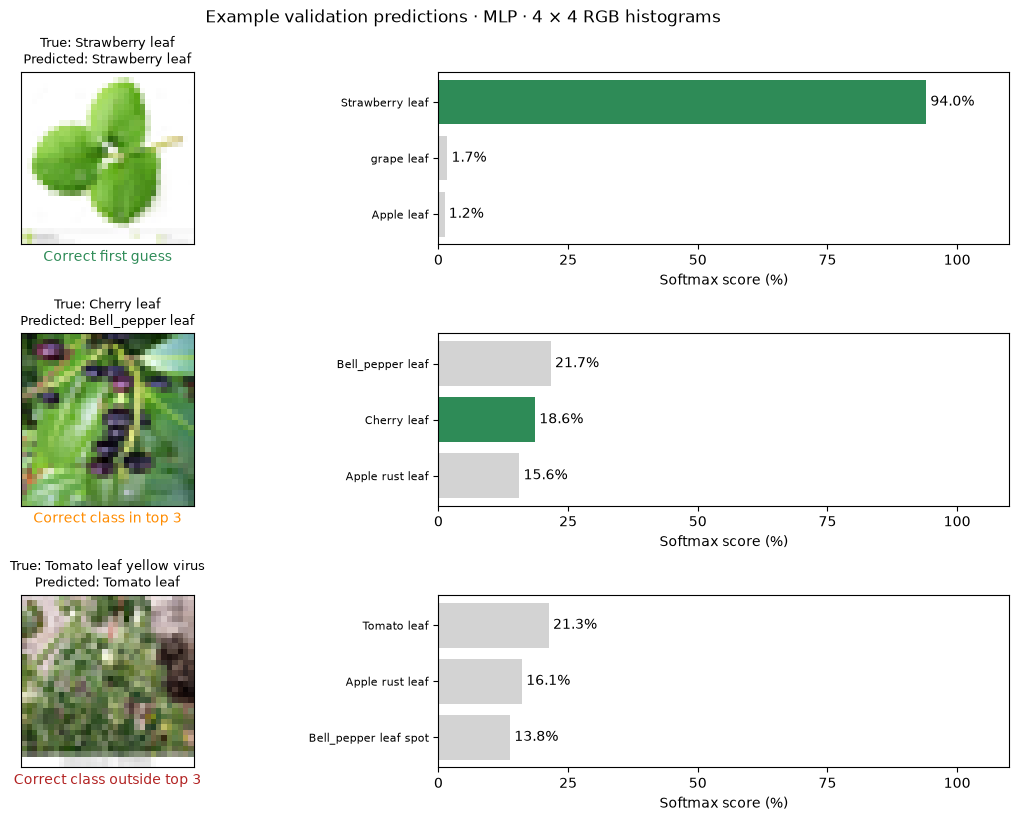

In [54]:
def plot_selected_mlp_predictions():
    selected_mlp_model.eval()
    with torch.inference_mode():
        logits = selected_mlp_model(selected_mlp_val_x)
        top_scores, top_ids = torch.softmax(logits, dim=1).topk(k=3, dim=1)

    top_labels = np.asarray(mlp_classes)[top_ids.cpu().numpy()]
    top_percentages = 100 * top_scores.cpu().numpy()
    true_labels = np.asarray(y_val)

    top1_correct = top_labels[:, 0] == true_labels
    top3_correct = (top_labels == true_labels[:, None]).any(axis=1)

    # Pick one example of each outcome when available.
    example_groups = [
        np.flatnonzero(top1_correct),
        np.flatnonzero(~top1_correct & top3_correct),
        np.flatnonzero(~top3_correct),
    ]
    examples = [group[0] for group in example_groups if len(group)]

    fig, axes = plt.subplots(
        len(examples), 2,
        figsize=(11, 2.7 * len(examples)),
        gridspec_kw={"width_ratios": [2, 3]},
        layout="constrained",
        squeeze=False,
    )

    for index, (image_ax, score_ax) in zip(examples, axes):
        true_label = true_labels[index]
        predicted_label = top_labels[index, 0]

        if top1_correct[index]:
            outcome, colour = "Correct first guess", "seagreen"
        elif top3_correct[index]:
            outcome, colour = "Correct class in top 3", "darkorange"
        else:
            outcome, colour = "Correct class outside top 3", "firebrick"

        # Display the RGB image before standardization or histogram extraction.
        image = np.asarray(X_val[index]).reshape(SIZE, SIZE, 3)
        image_ax.imshow(image)
        image_ax.set_title(
            f"True: {true_label}\nPredicted: {predicted_label}",
            fontsize=9,
        )
        image_ax.set_xlabel(outcome, color=colour)
        image_ax.set_xticks([])
        image_ax.set_yticks([])

        labels = top_labels[index]
        percentages = top_percentages[index]
        bar_colours = [
            "seagreen" if label == true_label else "lightgrey"
            for label in labels
        ]

        bars = score_ax.barh(labels, percentages, color=bar_colours)
        score_ax.bar_label(
            bars,
            labels=[f"{value:.1f}%" for value in percentages],
            padding=3,
        )
        score_ax.invert_yaxis()
        score_ax.set_xlim(0, 110)
        score_ax.set_xticks([0, 25, 50, 75, 100])
        score_ax.set_xlabel("Softmax score (%)")
        score_ax.tick_params(axis="y", labelsize=8)

    fig.suptitle(f"Example validation predictions · {selected_mlp_name}")
    plt.show()


plot_selected_mlp_predictions()

### Save and verify the selected MLP

We save the weights from the epoch with the highest validation macro F1,
along with the model settings, class order, and preprocessing details.
The checkpoint records which input representation won and stores the
scaler fitted on that representation's training features.

In the next cell, we reload the checkpoint, preprocess the same eight
validation images, and verify that the reloaded model reproduces the
original class scores without retraining.

In [56]:
MLP_CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)

selected_scaler = selected_mlp_run["scaler"]
selected_grid_size = selected_mlp_run["grid_size"]

selected_mlp_model.eval()
with torch.inference_mode():
    reference_logits = selected_mlp_model(selected_mlp_val_x[:8]).clone()

torch.save({
    "model_state": selected_mlp_model.state_dict(),
    "config": {
        "model_name": selected_mlp_name,
        "input_dim": selected_mlp_run["input_dim"],
        "hidden_width": selected_mlp_trial["Hidden Width"],
        "class_count": mlp_class_count,
        "activation": "ReLU",
        "classes": mlp_classes,
        "optimizer": "Adam",
        "class_weighting": selected_mlp_trial["Class Weighting"],
        "weight_decay": selected_mlp_trial["Weight Decay"],
        "learning_rate": MLP_LEARNING_RATE,
        "batch_size": MLP_BATCH_SIZE,
        "seed": MLP_SEED,
        "max_epochs": MLP_MAX_EPOCHS,
        "patience": MLP_PATIENCE,
        "best_epoch": selected_mlp_trial["Best Epoch"],
    },
    "preprocessing": {
        "representation": (
            "flattened_rgb" if selected_grid_size is None else "rgb_histogram"
        ),
        "image_size": [SIZE, SIZE],
        "colour_mode": "RGB",
        "resize": "Pillow Image.resize default",
        "flatten_order": "C",
        "pixel_divisor": 255.0,
        "grid_size": selected_grid_size,
        "bins_per_channel": (
            None if selected_grid_size is None else HIST_BINS_PER_CHANNEL
        ),
        "scaler_mean": torch.tensor(selected_scaler.mean_),
        "scaler_scale": torch.tensor(selected_scaler.scale_),
    },
    "validation_macro_f1": selected_mlp_trial["Val Macro F1"],
    "reference_logits": reference_logits,
}, MLP_CHECKPOINT)

print(f"Saved {selected_mlp_name} to {MLP_CHECKPOINT}")

Saved MLP · 4 × 4 RGB histograms to artifacts\stage2_mlp.pt


In [57]:
saved_mlp = torch.load(MLP_CHECKPOINT, map_location="cpu", weights_only=True)
saved_config = saved_mlp["config"]
saved_preprocessing = saved_mlp["preprocessing"]

# X_val contains the resized, flattened RGB values before standardization.
if saved_preprocessing["image_size"] != [SIZE, SIZE]:
    raise ValueError("The checkpoint image size does not match this notebook.")

reference_count = saved_mlp["reference_logits"].shape[0]
reference_pixels = X_val[:reference_count]
representation = saved_preprocessing["representation"]

if representation == "flattened_rgb":
    features = reference_pixels
elif representation == "rgb_histogram":
    if saved_preprocessing["bins_per_channel"] != HIST_BINS_PER_CHANNEL:
        raise ValueError("The checkpoint histogram bins do not match Cell 5.")
    features = rgb_histogram_features(
        reference_pixels,
        grid_size=saved_preprocessing["grid_size"],
    )
else:
    raise ValueError(f"Unknown input representation: {representation}")

# Apply the training-set scaler saved for this representation.
features = np.array(features, dtype=np.float32, copy=True)
features -= saved_preprocessing["scaler_mean"].numpy()
features /= saved_preprocessing["scaler_scale"].numpy()

reloaded_mlp = build_mlp(
    saved_config["input_dim"],
    saved_config["hidden_width"],
    saved_config["class_count"],
)
reloaded_mlp.load_state_dict(saved_mlp["model_state"])
reloaded_mlp.eval()

with torch.inference_mode():
    reloaded_logits = reloaded_mlp(torch.from_numpy(features))

torch.testing.assert_close(reloaded_logits, saved_mlp["reference_logits"])

predicted_labels = [
    saved_config["classes"][index]
    for index in reloaded_logits.argmax(dim=1).tolist()
]

print(f"Reload check passed: {saved_config['model_name']}")
print(f"Reproduced class scores for {reference_count} validation images.")
print(f"Saved validation macro F1: {saved_mlp['validation_macro_f1']:.4f}")
print("Predicted labels:", predicted_labels)

Reload check passed: MLP · 4 × 4 RGB histograms
Reproduced class scores for 8 validation images.
Saved validation macro F1: 0.1447
Predicted labels: ['Strawberry leaf', 'Tomato leaf', 'Squash Powdery mildew leaf', 'grape leaf', 'Peach leaf', 'grape leaf', 'Apple Scab Leaf', 'Apple rust leaf']


### MLP findings and limitations

The 4 × 4 RGB histogram MLP achieved the highest validation macro F1 among
the tested MLP variants, at 0.1447. It exceeded the flattened-pixel MLP
(0.1206) and the RBF SVM baseline (0.1283) on the same validation split.

Increasing the histogram grid resolution helped up to a point. Validation
macro F1 rose from 0.1355 for the global histogram to 0.1375 for quadrants
and 0.1447 for the 4 × 4 grid. It fell to 0.1268 for the 8 × 8 grid.

The selected model still showed substantial overfitting, with training
macro F1 of 0.9969 versus validation macro F1 of 0.1447. Histogram features
summarize colour within each region, but discard pixel arrangement within
regions and include background colours. The results come from one seed
and one validation split.

We select the 4 × 4 histogram MLP as the MLP candidate for the group’s
overall model comparison. Final model selection will also include the
tree models, using validation evidence.